# Combined Notebook: The Best Neighborhood In Pittsburgh

**Team Name:** Best Burgh

**By:** Benson Liu, Gunjan Baskota, Yixin Li

## Introduction

For our final project, our goal was to determine the "best" neighborhood in Pittsburgh using real data from the Western Pennsylvania Regional Data Center (WPRDC). We defined "bestness" through three distinct sub-metrics: **Popularity**, **Safety**, and **Value**.

- **Popularity (Benson)**: We measured popularity by looking at the raw number of occupied housing units in 2010. We initially considered total population, but decided to use occupied units to better reflect where households are actively choosing to live.

- **Safety (Gunjan)**: We measured safety by using the Part 1 crime rates per 100 persons data. We chose rates over raw crime counts to fairly compare large and small neighborhoods, as raw counts tend to favor larger areas.

- **Price (Yixin)**: We measured value by counting the number of high-value homes (valued at $500,000 or more). We considered crime rrates and green space, but decided to go with property values as they are a strong indicator of neighborhood appeal and economic vitality. 

By combining these three sub-metrics, we created a comprehensive view of what makes a neighborhood the "best" in Pittsburgh.

## The Metric

Our group combined three datasets from the WPRDC to evaluate the neighborhoods.

**1. Popularity Sub-Metric (Benson Liu)**
- **Dataset**: Pittsburgh SNAP Census Data - Housing 2010 (WPRDC)
- **Link**: https://data.wprdc.org/dataset/pgh/resource/94f8eda2-fa77-49a2-9190-3a6ed85fc561
- **Metric**: Total number of occupied housing units. A higher number of occupied. units means more people are actively living there, which makes it a popular neighborhood.

**2. Safety Sub-Metric (Gunjan Baskota)**
- **Dataset**: Pittsburgh SNAP Census Data - Public Safety 2010 (WPRDC)
- **Link**: https://data.wprdc.org/dataset/pgh/resource/bd152875-a14d-421a-8656-cc896a7e9074
- **Metric**: Part 1 Crime per 100 Persons. This measures the rate of serious crimes relative to the neighborhood's population. A lower rate means a safer neighborhood. We also ranked neighborhoods from lowest to highest rate for our visualization.

**3. Value Sub-Metric (Yixin Li)**
- **Dataset**: Pittsburgh American Community Survey 2015 - Miscellaneous Data - Housing Unit Value
- **Link**: https://data.wprdc.org/dataset/5b18c198-474c-4723-b735-cc5220ad43cc/resource/13982f58-e618-400c-8f69-6a32dbd7c68f/
- **Metric**: Total Number of High-Value Homes. This tracks the number of homes valued at $500,000 or more. A higher number of homes indicates a superior neighborhood environment.

## The Best Neighborhood

To determine the best neighborhood, we analyzed each sub-metric individually and then looked at the results together.


**Popularity Results (Benson)**:
Shadyside is the most popular neighborhood with 8,185 occupied housing units and a population of 13,915. It is followed by Squirrel Hill South (7,135 units) and Brookline (6,183 units).

<Axes: title={'center': 'Top 10 Neighborhoods by Occupied Units (2010)'}, xlabel='Neighborhood'>

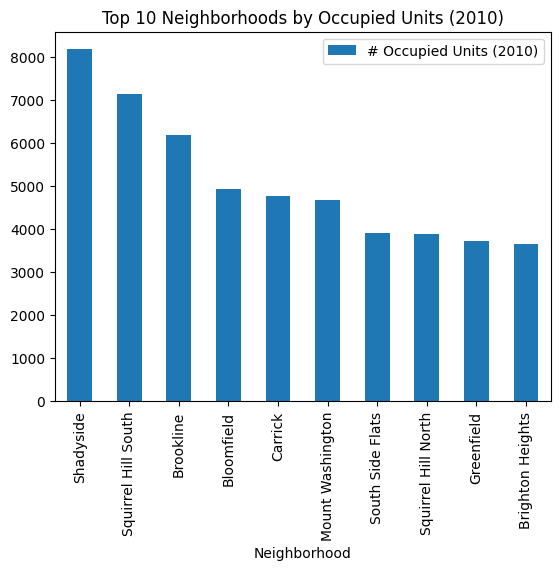

In [1]:
import pandas as pd

# load the dataset from the file named 'popularity.csv'
df = pd.read_csv("popularity.csv")

# keeps three (neighborhood, population, and occupied units) out of 29 columns from the dataset
pop_data = df[['Neighborhood', 'Population (2010)', '# Occupied Units (2010)']]

# sorts the dataset in descending order based on the number of occupied units
sorted_data = pop_data.sort_values('# Occupied Units (2010)', ascending=False)

# prints out the top 10 neighborhoods
top_10_neighborhoods = sorted_data.head(10)

# creates a bar chart that displays the top 10 neighborhoods by occupied units in 2010
top_10_neighborhoods.plot.bar(x='Neighborhood', y='# Occupied Units (2010)', title='Top 10 Neighborhoods by Occupied Units (2010)')

**Safety Results (Gunjan)**:
Fairywood is the safest neighborhood with just 0.3 Part 1 crimes per 100 persons, followed by New Homestead (0.7) and Lincoln Place (1.0). This shows that smaller neighborhoods tend to have the lowest rates, while busy areas rank much higher.

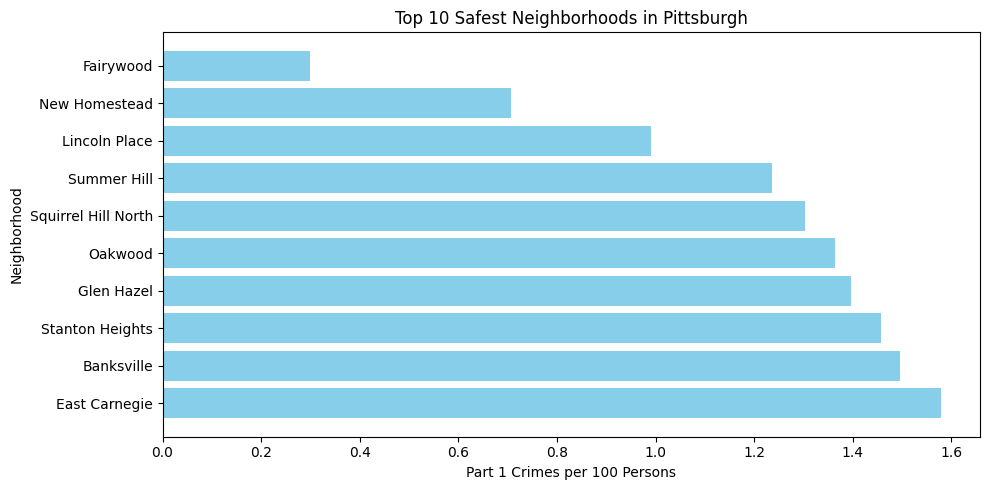

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# load crime data
safety_df = pd.read_csv("safety.csv")

top_10 = safety_df.sort_values("Part 1 Crime per 100 Persons (2010)").head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_10['Neighborhood'], top_10['Part 1 Crime per 100 Persons (2010)'], color='skyblue')
plt.xlabel('Part 1 Crimes per 100 Persons')
plt.ylabel('Neighborhood')
plt.title('Top 10 Safest Neighborhoods in Pittsburgh')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Value Results (Yixin)**:
Squirrel Hill North ranks first with 734 high-value homes, followed by Squirrel Hill South (590) and Shadyside (407). This shows that proximity to institutions like CMU and Pitt tends to drive higher property valuations.

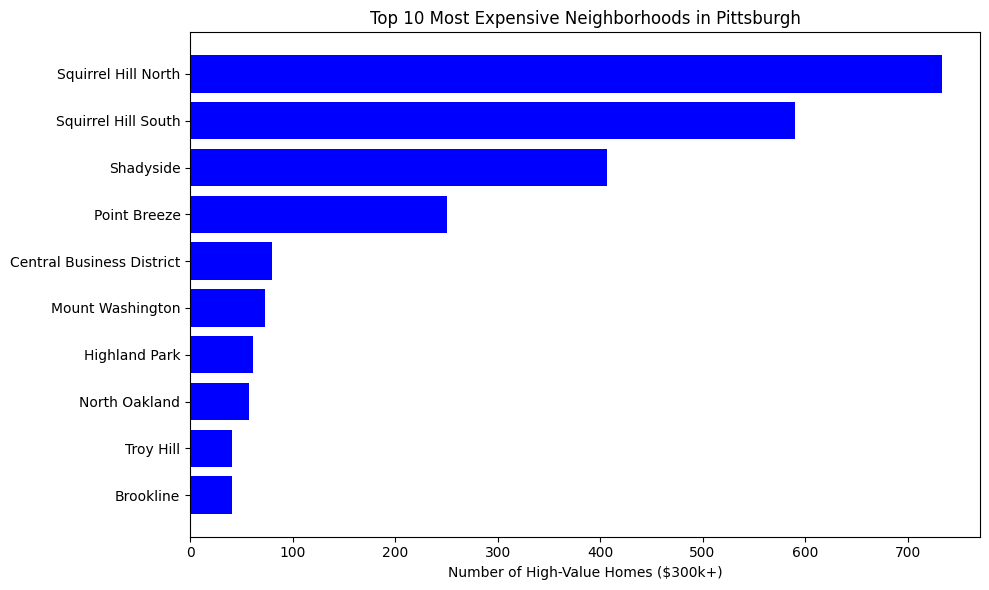

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset from the file named 'value.csv'
df = pd.read_csv("value.csv")


# Find all of the houses that above $500,000
high_value_cols = [
    "Estimate; Total: - $500,000 to $749,999",
    "Estimate; Total: - $750,000 to $999,999",
    "Estimate; Total: - $1,000,000 to $1,499,999",
    "Estimate; Total: - $1,500,000 to $1,999,999",
    "Estimate; Total: - $2,000,000 or more",
]

# Ensure columns are numeric; convert errors to NaN and fill with 0
for col in high_value_cols:
  df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Calculate the total number of high-value homes per neighborhood
df["High_Value_Total"] = df[high_value_cols].sum(axis=1)

# Find the top 10 most expensive neighborhoods
top_expensive_neighborhoods = df[["Neighborhood", "High_Value_Total"]].sort_values(
    by="High_Value_Total", ascending=False
)

# Graph top 10
top10 = top_expensive_neighborhoods.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top10["Neighborhood"][::-1],
    top10["High_Value_Total"][::-1],
    color="blue",
)
plt.xlabel("Number of High-Value Homes ($300k+)")
plt.title("Top 10 Most Expensive Neighborhoods in Pittsburgh")
plt.tight_layout()

# Graph
plt.show()

### The Overall Best Neighborhood
When we combine these sub-metrics, we notice that a few neighborhoods stand out, but **Shadyside** takes the overall win.

- **Why Shadyside wins**: It is the most actively lived-in neighborhood in Pittsburgh (#1 in popularity with 8,185 occupied units) while still maintaining a strong top-3 ranking in value. However, its safety is much lower because busy places tend to have more reported crimes.
- **Why Squirrel Hill comes in second**: It dominates value (#1 and #2) and ranks highly in popularity (#2 and #8). It is also safer than Shadyside due to its data from the Part 1 crime rates.
- **Why Fairywood doesn't win overall**: It is the safest neighborhood by far, but it is a small area that does not compete in popularity or value, which makes it a poor option when considering the best neighborhood overall.

Because Shadyside is the most actively lived-in neighborhood and maintains a top-3 high-value ranking, it wins overall all. Although Squirrel Hill and Fairywood beat it on safety, it is the closest neighborhood that we have found that shows satisfying results in all three sub-metrics.

## Conclusion
**Benson Liu**:
The data-driven popularity result is Shadyside. I don't have a personal favorite neighborhood, but if I had to pick one, I would pick Squirrel Hill South. Comparing the two, my favorite is ranked #2 on this popularity sub-metric, which is right behind Shadyside. This taught me that popular can be shown as a neighborhood with many people living in it. It is different than having a count of the people that visit a preferred neighborhood. Although Squirrel Hill South doesn't have the most occupied units, it still has a massive population. Ultimately, this is why our group chose to combine this sub-metric with other factors like safety and value to determine the best neighborhood overall.

**Gunjan Baskota**:
Fairywood being the best neighborhood based on crime data is very different from my personal favorites like Oakland or Shadyside. My favorites are busy, walkable places with lots of students and foot traffic, which is exactly why they rank much higher in crime rate. The data seem to reward smaller neighborhoods, while my personal preference favors activity and convenience. Although the two differs, the gap makes sense because a lively neighborhood will always have more reported crimes than a quiet one, and the definition of bestness still needs to be considered by other factors like price and popularity.

**Yixin Li**:
My personal favorite neighborhood is Shadyside, which ranks third with 407 high-value homes and is right behind both Squirrel Hill neighborhoods. This gap shows the difference between a data-driven ranking differs from personal preference. Both agree that Shadyside is a strong neighborhood, but the data puts Squirrel Hill on top because it has more high-value homes, not because it is a better place to live.